# LoRA e QLoRA: o que aprende e o que fica congelado?

Vamos adaptar **a mesma base à mesma tarefa**, mudando quais pesos podem aprender.

| Método | O que será atualizado? | Como usamos a base? |
|---|---|---|
| Ajuste completo | Todos os pesos | Valores em float32 |
| LoRA | Pequenas matrizes adicionais, chamadas de adapter | Pesos originais congelados |
| QLoRA didática | O adapter LoRA | Valores da base aproximados por quantização NF4 |

PEFT é a família de ajustes que treinam uma parte pequena dos parâmetros. Aqui estudamos LoRA, uma das possibilidades. Adapter é a parte específica desta adaptação que podemos guardar junto de sua configuração.


In [2]:
import os
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")   # matrizes pequenas: 1 thread é mais rápido e mais reprodutível
import copy
import math
import re
import time

import numpy as np
import matplotlib.pyplot as plt

TEAL, AMBER, INK, RED, CINZA = "#17897B", "#E08A3C", "#0F1C2E", "#C0392B", "#8494A6"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("Bibliotecas prontas.")
from html import escape
try:
    from IPython.display import HTML, display
except ImportError:
    display = None
_blocos = []
def mostrar(titulo,colunas,linhas,nota=""):
    enc=lambda x:escape(str(x)).replace("\n","<br>")
    html=f"<section><h3>{enc(titulo)}</h3><p>{enc(nota)}</p><table><thead><tr>"
    html+="".join(f"<th>{enc(c)}</th>" for c in colunas)+"</tr></thead><tbody>"
    html+="".join("<tr>"+"".join(f"<td>{enc(v)}</td>" for v in linha)+"</tr>" for linha in linhas)
    html+="</tbody></table></section>"
    _blocos.append(html)
    if display is not None:display(HTML(html))
    else:
        print("\n"+titulo+"\n"+nota)
        print(" | ".join(colunas))
        for linha in linhas:print(" | ".join(str(v) for v in linha))
def pct(v):return f"{v:.1%}".replace(".",",")
def numero(v):return f"{v:,}".replace(",",".")

Bibliotecas prontas.


## 1. O ponto de partida e a tarefa

Usamos o mini-GPT do laboratório de SFT, com 132.352 parâmetros. Ele lê textos sintéticos sobre 42 países e aprende a prever o próximo token. As listas de quiz sem respostas favorecem a continuação de perguntas.

A tarefa de adaptação é responder a pedidos de capital, língua e continente no formato de chat. Primeiro veja a base completar uma frase. Isso demonstra o fato nessa consulta específica, sem provar que o modelo atenderia qualquer instrução.

In [3]:
#@title O laboratório da semana de SFT: mundo, tokens, mini-GPT, treino, chat template e avaliação (execute; leitura opcional)
# pais, "de", "em", artigo, capital, lingua mais falada, continente
PAISES = [
    ("Brasil", "do", "no", "O", "Brasília", "português", "América do Sul"),
    ("Argentina", "da", "na", "A", "Buenos Aires", "espanhol", "América do Sul"),
    ("Chile", "do", "no", "O", "Santiago", "espanhol", "América do Sul"),
    ("Peru", "do", "no", "O", "Lima", "espanhol", "América do Sul"),
    ("Colômbia", "da", "na", "A", "Bogotá", "espanhol", "América do Sul"),
    ("Venezuela", "da", "na", "A", "Caracas", "espanhol", "América do Sul"),
    ("Uruguai", "do", "no", "O", "Montevidéu", "espanhol", "América do Sul"),
    ("Equador", "do", "no", "O", "Quito", "espanhol", "América do Sul"),
    ("México", "do", "no", "O", "Cidade do México", "espanhol", "América do Norte"),
    ("Canadá", "do", "no", "O", "Ottawa", "inglês", "América do Norte"),
    ("Portugal", "de", "em", "", "Lisboa", "português", "Europa"),
    ("Espanha", "da", "na", "A", "Madri", "espanhol", "Europa"),
    ("França", "da", "na", "A", "Paris", "francês", "Europa"),
    ("Itália", "da", "na", "A", "Roma", "italiano", "Europa"),
    ("Alemanha", "da", "na", "A", "Berlim", "alemão", "Europa"),
    ("Grécia", "da", "na", "A", "Atenas", "grego", "Europa"),
    ("Polônia", "da", "na", "A", "Varsóvia", "polonês", "Europa"),
    ("Suécia", "da", "na", "A", "Estocolmo", "sueco", "Europa"),
    ("Noruega", "da", "na", "A", "Oslo", "norueguês", "Europa"),
    ("Finlândia", "da", "na", "A", "Helsinque", "finlandês", "Europa"),
    ("Dinamarca", "da", "na", "A", "Copenhague", "dinamarquês", "Europa"),
    ("Áustria", "da", "na", "A", "Viena", "alemão", "Europa"),
    ("Hungria", "da", "na", "A", "Budapeste", "húngaro", "Europa"),
    ("Romênia", "da", "na", "A", "Bucareste", "romeno", "Europa"),
    ("Croácia", "da", "na", "A", "Zagreb", "croata", "Europa"),
    ("Japão", "do", "no", "O", "Tóquio", "japonês", "Ásia"),
    ("China", "da", "na", "A", "Pequim", "chinês", "Ásia"),
    ("Coreia do Sul", "da", "na", "A", "Seul", "coreano", "Ásia"),
    ("Tailândia", "da", "na", "A", "Bangkok", "tailandês", "Ásia"),
    ("Vietnã", "do", "no", "O", "Hanói", "vietnamita", "Ásia"),
    ("Irã", "do", "no", "O", "Teerã", "persa", "Ásia"),
    ("Arábia Saudita", "da", "na", "A", "Riad", "árabe", "Ásia"),
    ("Índia", "da", "na", "A", "Nova Délhi", "hindi", "Ásia"),
    ("Iraque", "do", "no", "O", "Bagdá", "árabe", "Ásia"),
    ("Malásia", "da", "na", "A", "Kuala Lumpur", "malaio", "Ásia"),
    ("Angola", "de", "em", "", "Luanda", "português", "África"),
    ("Marrocos", "do", "no", "O", "Rabat", "árabe", "África"),
    ("Argélia", "da", "na", "A", "Argel", "árabe", "África"),
    ("Quênia", "do", "no", "O", "Nairóbi", "suaíli", "África"),
    ("Tunísia", "da", "na", "A", "Túnis", "árabe", "África"),
    ("Austrália", "da", "na", "A", "Camberra", "inglês", "Oceania"),
    ("Nova Zelândia", "da", "na", "A", "Wellington", "inglês", "Oceania"),
]
# o corpus fala destes paises, mas nunca diz a capital deles
SEM_CAPITAL = [
    ("Mongólia", "da", "na", "A", None, "mongol", "Ásia"),
    ("Nepal", "do", "no", "O", None, "nepalês", "Ásia"),
    ("Islândia", "da", "na", "A", None, "islandês", "Europa"),
    ("Bolívia", "da", "na", "A", None, "espanhol", "América do Sul"),
    ("Tanzânia", "da", "na", "A", None, "suaíli", "África"),
    ("Eslováquia", "da", "na", "A", None, "eslovaco", "Europa"),
    ("Lituânia", "da", "na", "A", None, "lituano", "Europa"),
    ("Laos", "do", "no", "O", None, "laosiano", "Ásia"),
    ("Omã", "de", "em", "", None, "árabe", "Ásia"),
    ("Sudão", "do", "no", "O", None, "árabe", "África"),
]
# paises que so aparecem no pre-treino continuado (fora do corpus original)
NOVOS = [
    ("Bulgária", "da", "na", "A", "Sófia", "búlgaro", "Europa"),
    ("Sérvia", "da", "na", "A", "Belgrado", "sérvio", "Europa"),
    ("Albânia", "da", "na", "A", "Tirana", "albanês", "Europa"),
    ("Jordânia", "da", "na", "A", "Amã", "árabe", "Ásia"),
    ("Líbano", "do", "no", "O", "Beirute", "árabe", "Ásia"),
    ("Somália", "da", "na", "A", "Mogadíscio", "somali", "África"),
]
RELACOES = ("capital", "lingua", "continente")

# frases do texto de pre-treino: varias formas para o mesmo fato
FRASES = {
    "capital": ["A capital {de} {P} é {C}.", "{C} é a capital {de} {P}.",
                "{Art}{P} tem {C} como capital.", "{Art}{P} tem como capital {C}."],
    "lingua": ["{Em} {P}, fala-se {L}.", "A língua mais falada {de} {P} é o {L}.",
               "O {L} é a língua mais falada {de} {P}.", "A maioria das pessoas {em} {P} fala {L}."],
    "continente": ["{Art}{P} fica na {K}.", "{Art}{P} é um país da {K}.",
                   "Um dos países da {K} é {art}{P}.", "Na {K} fica {art}{P}."],
}
# pedidos: as formas 0-4 aparecem no ajuste; 5 e 6 ficam guardadas para teste
PERGUNTAS = {
    "capital": ["Qual é a capital {de} {P}?", "Qual a capital {de} {P}?",
                "Me diga a capital {de} {P}.", "Você sabe qual é a capital {de} {P}?",
                "{P}: qual é a capital?", "{P} tem qual capital?",
                "A capital {de} {P} é qual?"],
    "lingua": ["Qual é a língua mais falada {de} {P}?", "Que língua se fala {em} {P}?",
               "Me diga a língua mais falada {de} {P}.", "Você sabe que língua se fala {em} {P}?",
               "{P}: qual é a língua mais falada?", "{P} fala qual língua?",
               "A língua mais falada {de} {P} é qual?"],
    "continente": ["Em que continente fica {art}{P}?", "Qual é o continente {de} {P}?",
                   "Me diga o continente {de} {P}.", "Você sabe em que continente fica {art}{P}?",
                   "{P}: qual é o continente?", "{Art}{P} fica em qual continente?",
                   "O continente {de} {P} é qual?"],
}
RESPOSTA = {"capital": "A capital {de} {P} é {C}.", "lingua": "{Em} {P}, fala-se {L}.",
            "continente": "{Art}{P} fica na {K}."}
SEGUIMENTO = {"capital": "E a capital?", "lingua": "E a língua?", "continente": "E o continente?"}
NAO_SEI = "Não sei a capital {de} {P}."
SISTEMA = "Responda em uma frase."


def preencher(modelo, pais):
    nome, de, em, art, capital, lingua, continente = pais
    return modelo.format(P=nome, de=de, em=em, Em=em.capitalize(),
                         Art=art + " " if art else "", art=art.lower() + " " if art else "",
                         C=capital, L=lingua, K=continente)

def gerar_corpus(paises, semente=0, textos_por_pais=24, quizzes=240):
    """Documentos de pre-treino: verbetes curtos e listas de perguntas sem resposta."""
    rng = np.random.default_rng(semente)
    docs = []
    for pais in paises:
        rels = RELACOES if pais[4] else ("lingua", "continente")
        for _ in range(textos_por_pais):
            frases = [preencher(FRASES[r][rng.integers(4)], pais) for r in rels]
            rng.shuffle(frases)
            docs.append(" ".join(frases))
    for _ in range(quizzes):
        linhas = ["Quiz de geografia:"]
        for i in range(int(rng.integers(4, 8))):
            pais, r = paises[rng.integers(len(paises))], RELACOES[rng.integers(3)]
            linhas.append("%d. %s" % (i + 1, preencher(PERGUNTAS[r][rng.integers(2)], pais)))
        docs.append("\n".join(linhas))
    rng.shuffle(docs)
    return docs

ESPECIAIS = ["<|endoftext|>", "<|im_start|>", "<|im_end|>", "<|pad|>"]
_PADRAO = re.compile(r"<\|[a-z_]+\|>|\n|\w+|[^\w\s]")


def quebrar(texto):
    """Um token por palavra, pontuação, quebra de linha ou token especial."""
    return _PADRAO.findall(texto)


def juntar(tokens):
    s = " ".join(tokens)
    s = re.sub(r" ?\n ?", "\n", s)
    s = re.sub(r" ([.,?:!])", r"\1", s).replace(" - ", "-")
    return s.replace("<|im_start|> ", "<|im_start|>").replace(" <|im_end|>", "<|im_end|>")


class Tokenizador:
    def __init__(self, textos):
        palavras = sorted({t for texto in textos for t in quebrar(texto)} - set(ESPECIAIS))
        self.vocab = ESPECIAIS + palavras
        self.id = {t: i for i, t in enumerate(self.vocab)}

    def codificar(self, texto):
        return [self.id[t] for t in quebrar(texto)]

    def decodificar(self, ids):
        return juntar([self.vocab[i] for i in ids])


def textos_do_mundo(*corpora):
    """Tudo o que o modelo poderá ler. Como num LLM real, o vocabulário é fixado antes do treino."""
    textos = [d for corpus in corpora for d in corpus]
    for pais in PAISES + SEM_CAPITAL + NOVOS:
        for r in RELACOES:
            textos += [preencher(f, pais) for f in PERGUNTAS[r]]
            if pais[4] is not None or r != "capital":
                textos.append(preencher(RESPOSTA[r], pais))
        textos.append(preencher(NAO_SEI, pais))
    return textos + list(SEGUIMENTO.values()) + [SISTEMA, "system user assistant :\n"]

def layernorm(x, g, b, eps=1e-5):
    xc = x - x.mean(-1, keepdims=True)
    rstd = 1.0 / np.sqrt((xc * xc).mean(-1, keepdims=True) + eps)
    xh = xc * rstd
    return xh * g + b, (xh, rstd)


def layernorm_volta(dy, g, cache):
    xh, rstd = cache
    d = dy.shape[-1]
    dxh = dy * g
    dx = rstd * (dxh - dxh.mean(-1, keepdims=True) - xh * (dxh * xh).mean(-1, keepdims=True))
    return dx, (dy * xh).reshape(-1, d).sum(0), dy.reshape(-1, d).sum(0)


class MiniGPT:
    """Decoder-only como o GPT-2, em miniatura: embeddings de token e posição,
    blocos com self-attention mascarada e MLP, LayerNorm antes de cada parte.
    (O GPT-2 usa GELU na MLP; aqui usamos ReLU, mais simples e mais rápida em numpy.)"""

    def __init__(self, V, contexto=72, d=64, camadas=2, cabecas=4, semente=0, tipo=np.float32):
        rng = np.random.default_rng(semente)
        n = lambda *forma, dp=0.02: (rng.standard_normal(forma) * dp).astype(tipo)
        um, zero = lambda k: np.ones(k, tipo), lambda k: np.zeros(k, tipo)
        res = 0.02 / math.sqrt(2 * camadas)          # projeções que somam no resíduo
        p = {"wte": n(V, d), "wpe": n(contexto, d)}
        for l in range(camadas):
            p.update({"%d.ln1_g" % l: um(d), "%d.ln1_b" % l: zero(d),
                      "%d.qkv" % l: n(d, 3 * d), "%d.qkv_b" % l: zero(3 * d),
                      "%d.o" % l: n(d, d, dp=res), "%d.o_b" % l: zero(d),
                      "%d.ln2_g" % l: um(d), "%d.ln2_b" % l: zero(d),
                      "%d.fc" % l: n(d, 4 * d), "%d.fc_b" % l: zero(4 * d),
                      "%d.pr" % l: n(4 * d, d, dp=res), "%d.pr_b" % l: zero(d)})
        p.update({"lnf_g": um(d), "lnf_b": zero(d), "saida": n(d, V)})
        self.p, self.V, self.T, self.d, self.L, self.H = p, V, contexto, d, camadas, cabecas
        # -1e9 acima da diagonal: a posição t não enxerga as posições depois dela
        self.futuro = np.triu(np.full((contexto, contexto), -1e9, tipo), 1)

    def n_params(self):
        return int(sum(v.size for v in self.p.values()))

    def forward(self, X, guardar=True):
        p, (B, T), d, H = self.p, X.shape, self.d, self.H
        dh = d // H
        x = p["wte"][X] + p["wpe"][:T]
        caches = []
        for l in range(self.L):
            a, c1 = layernorm(x, p["%d.ln1_g" % l], p["%d.ln1_b" % l])
            qkv = a @ p["%d.qkv" % l] + p["%d.qkv_b" % l]
            q, k, v = qkv.reshape(B, T, 3, H, dh).transpose(2, 0, 3, 1, 4)
            att = q @ k.transpose(0, 1, 3, 2)
            att *= 1.0 / math.sqrt(dh)
            att += self.futuro[:T, :T]                 # máscara causal
            att -= att.max(-1, keepdims=True)
            np.exp(att, out=att)
            att /= att.sum(-1, keepdims=True)           # softmax: pesos da atenção
            y = (att @ v).transpose(0, 2, 1, 3).reshape(B, T, d)
            x = x + y @ p["%d.o" % l] + p["%d.o_b" % l]
            m, c2 = layernorm(x, p["%d.ln2_g" % l], p["%d.ln2_b" % l])
            h = m @ p["%d.fc" % l] + p["%d.fc_b" % l]
            gh = np.maximum(h, 0)
            x = x + gh @ p["%d.pr" % l] + p["%d.pr_b" % l]
            if guardar:
                caches.append((a, c1, q, k, v, att, y, m, c2, h, gh))
        xf, cf = layernorm(x, p["lnf_g"], p["lnf_b"])
        if guardar:
            self._cache = (X, caches, xf, cf)
        return xf @ p["saida"]

    def backward(self, dlogits):
        X, caches, xf, cf = self._cache
        p, (B, T), d, H = self.p, X.shape, self.d, self.H
        dh = d // H
        g = {"saida": xf.reshape(-1, d).T @ dlogits.reshape(-1, self.V)}
        dx, g["lnf_g"], g["lnf_b"] = layernorm_volta(dlogits @ p["saida"].T, p["lnf_g"], cf)
        for l in reversed(range(self.L)):
            a, c1, q, k, v, att, y, m, c2, h, gh = caches[l]
            g["%d.pr" % l] = gh.reshape(-1, 4 * d).T @ dx.reshape(-1, d)
            g["%d.pr_b" % l] = dx.reshape(-1, d).sum(0)
            dh_ = (dx @ p["%d.pr" % l].T) * (h > 0)
            g["%d.fc" % l] = m.reshape(-1, d).T @ dh_.reshape(-1, 4 * d)
            g["%d.fc_b" % l] = dh_.reshape(-1, 4 * d).sum(0)
            dm, g["%d.ln2_g" % l], g["%d.ln2_b" % l] = layernorm_volta(
                dh_ @ p["%d.fc" % l].T, p["%d.ln2_g" % l], c2)
            dx = dx + dm
            g["%d.o" % l] = y.reshape(-1, d).T @ dx.reshape(-1, d)
            g["%d.o_b" % l] = dx.reshape(-1, d).sum(0)
            dy = (dx @ p["%d.o" % l].T).reshape(B, T, H, dh).transpose(0, 2, 1, 3)
            ds = dy @ v.transpose(0, 1, 3, 2)
            dv = att.transpose(0, 1, 3, 2) @ dy
            ds -= (ds * att).sum(-1, keepdims=True)     # volta pela softmax
            ds *= att
            ds *= 1.0 / math.sqrt(dh)
            dq, dk = ds @ k, ds.transpose(0, 1, 3, 2) @ q
            dqkv = np.stack([dq, dk, dv]).transpose(1, 3, 0, 2, 4).reshape(B, T, 3 * d)
            g["%d.qkv" % l] = a.reshape(-1, d).T @ dqkv.reshape(-1, 3 * d)
            g["%d.qkv_b" % l] = dqkv.reshape(-1, 3 * d).sum(0)
            da, g["%d.ln1_g" % l], g["%d.ln1_b" % l] = layernorm_volta(
                dqkv @ p["%d.qkv" % l].T, p["%d.ln1_g" % l], c1)
            dx = dx + da
        g["wpe"] = np.zeros_like(p["wpe"])
        g["wpe"][:T] = dx.sum(0)
        g["wte"] = np.zeros_like(p["wte"])
        np.add.at(g["wte"], X, dx)
        return g


def perda_e_gradiente(modelo, X, Y, M):
    """Entropia cruzada média só nas posições com M = 1 (os alvos)."""
    z = modelo.forward(X)
    z -= z.max(-1, keepdims=True)
    e = np.exp(z)
    soma = e.sum(-1, keepdims=True)
    B, T = Y.shape
    linhas, colunas = np.arange(B)[:, None], np.arange(T)[None, :]
    nll = np.log(soma[..., 0]) - z[linhas, colunas, Y]
    n = M.sum()
    dz = e / soma                                   # softmax
    dz[linhas, colunas, Y] -= 1.0                   # p - one_hot
    dz *= (M / n)[..., None]                        # só as posições-alvo contam
    return float((nll * M).sum() / n), modelo.backward(dz)


def perda_media(modelo, X, Y, M, bloco=128):
    tot, n = 0.0, 0.0
    for i in range(0, len(X), bloco):
        z = modelo.forward(X[i:i + bloco], guardar=False)
        z = z - z.max(-1, keepdims=True)
        logp = z - np.log(np.exp(z).sum(-1, keepdims=True))
        Yb, Mb = Y[i:i + bloco], M[i:i + bloco]
        nll = -np.take_along_axis(logp, Yb[..., None], -1)[..., 0]
        tot += float((nll * Mb).sum())
        n += float(Mb.sum())
    return tot / n

class Adam:
    def __init__(self, params, b1=0.9, b2=0.95, eps=1e-8):
        self.m = {k: np.zeros_like(v) for k, v in params.items()}
        self.v = {k: np.zeros_like(v) for k, v in params.items()}
        self.b1, self.b2, self.eps, self.t = b1, b2, eps, 0

    def passo(self, params, grads, lr):
        self.t += 1
        c1, c2 = 1 - self.b1 ** self.t, 1 - self.b2 ** self.t
        for k, w in params.items():
            m, v, gk = self.m[k], self.v[k], grads[k]
            m *= self.b1
            m += (1 - self.b1) * gk
            v *= self.b2
            v += (1 - self.b2) * gk * gk
            w -= (lr / c1) * m / (np.sqrt(v / c2) + self.eps)


def taxa(passo, total, lr_max, aquecimento):
    """Aquecimento linear e depois decaimento cosseno até 10% do pico."""
    if passo < aquecimento:
        return lr_max * (passo + 1) / aquecimento
    prog = (passo - aquecimento) / max(1, total - aquecimento)
    return lr_max * (0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * prog)))

def treinar(modelo, proximo_lote, passos, lr_max, aquecimento=50, avaliar=None, avaliar_cada=50):
    """O mesmo laço serve para pre-treino e SFT: só muda o que proximo_lote() devolve."""
    otimizador = Adam(modelo.p)
    historico = {"passo": [], "perda_lote": []}
    for passo in range(passos + 1):
        if avaliar is not None and (passo % avaliar_cada == 0 or passo == passos):
            historico["passo"].append(passo)
            for nome, valor in avaliar(modelo).items():
                historico.setdefault(nome, []).append(valor)
        if passo == passos:
            break
        X, Y, M = proximo_lote()                                    # 1. um lote
        perda, grads = perda_e_gradiente(modelo, X, Y, M)           # 2. previsão, perda e gradiente
        otimizador.passo(modelo.p, grads, taxa(passo, passos, lr_max, aquecimento))  # 3. atualização
        historico["perda_lote"].append(perda)
    return historico

def lotes_de_texto(ids, B, T, rng):
    """Pre-treino: janelas aleatórias do texto corrido; todo token é alvo."""
    ids = np.asarray(ids)
    def proximo():
        inicio = rng.integers(0, len(ids) - T - 1, B)
        janelas = np.stack([ids[i:i + T + 1] for i in inicio])
        return janelas[:, :-1], janelas[:, 1:], np.ones((B, T), np.float32)
    return proximo


def lotes_de_mistura(fontes, T, rng):
    """Mistura de fontes no mesmo lote: fontes = [(ids, linhas_por_lote), ...]."""
    proximos = [lotes_de_texto(ids, n, T, rng) for ids, n in fontes]
    def proximo():
        partes = [p() for p in proximos]
        return tuple(np.concatenate([parte[i] for parte in partes]) for i in range(3))
    return proximo


def janelas_fixas(ids, T):
    """Conjunto fixo de janelas (para medir a perda sempre nos mesmos trechos)."""
    ids = np.asarray(ids)
    n = (len(ids) - 1) // T
    X = np.stack([ids[i * T:i * T + T] for i in range(n)])
    Y = np.stack([ids[i * T + 1:i * T + T + 1] for i in range(n)])
    return X, Y, np.ones(X.shape, np.float32)

def aplicar_template(mensagens, abrir_resposta=False):
    """ChatML, o formato usado por modelos como o Qwen."""
    texto = "".join("<|im_start|>%s\n%s<|im_end|>\n" % (m["role"], m["content"]) for m in mensagens)
    if abrir_resposta:
        texto += "<|im_start|>assistant\n"
    return texto

def tokens_e_alvos(tok, mensagens, modo="resposta"):
    """Tokens da conversa e máscara de alvos.
    modo="resposta": só o texto do assistant e o <|im_end|> que o encerra contam na perda;
    modo="sem_fim":  igual, mas sem o <|im_end|>;
    modo="tudo":     todos os tokens contam (como no pre-treino)."""
    ids, alvo = [], []
    for m in mensagens:
        cabeca = tok.codificar("<|im_start|>%s\n" % m["role"])
        corpo = tok.codificar(m["content"])
        fim = tok.codificar("<|im_end|>")
        quebra = tok.codificar("\n")
        resp = m["role"] == "assistant"
        ids += cabeca + corpo + fim + quebra
        if modo == "tudo":
            alvo += [1] * (len(cabeca) + len(corpo) + len(fim) + len(quebra))
        else:
            alvo += [0] * len(cabeca) + [int(resp)] * len(corpo)
            alvo += [int(resp and modo == "resposta")] * len(fim) + [0] * len(quebra)
    return np.array(ids), np.array(alvo, np.float32)

def lotes_de_conversas(exemplos, B, rng, pad, texto_ids=None, linhas_texto=0):
    """SFT: cada linha do lote é uma conversa, completada com <|pad|> (que nunca é alvo).
    linhas_texto > 0 mistura janelas do texto de pre-treino no lote (replay)."""
    ordem, pos = rng.permutation(len(exemplos)), 0
    def proximo():
        nonlocal ordem, pos
        n = min(B - linhas_texto, len(exemplos))
        if pos + n > len(exemplos):
            ordem, pos = rng.permutation(len(exemplos)), 0
        escolha = ordem[pos:pos + n]
        pos += n
        T = max(len(exemplos[i][0]) for i in escolha) - 1
        X = np.full((n + linhas_texto, T), pad)
        Y = np.full((n + linhas_texto, T), pad)
        M = np.zeros((n + linhas_texto, T), np.float32)
        for j, i in enumerate(escolha):
            ids, alvo = exemplos[i]
            X[j, :len(ids) - 1], Y[j, :len(ids) - 1], M[j, :len(ids) - 1] = ids[:-1], ids[1:], alvo[1:]
        for j in range(n, n + linhas_texto):
            ini = rng.integers(0, len(texto_ids) - T - 1)
            X[j], Y[j], M[j] = texto_ids[ini:ini + T], texto_ids[ini + 1:ini + T + 1], 1.0
        return X, Y, M
    return proximo


def conversas_fixas(exemplos, pad):
    """Um único lote com todas as conversas (para medir a perda sempre no mesmo conjunto)."""
    L = max(len(i) for i, _ in exemplos)
    X = np.full((len(exemplos), L - 1), pad)
    Y = X.copy()
    M = np.zeros(X.shape, np.float32)
    for j, (i, a) in enumerate(exemplos):
        X[j, :len(i) - 1], Y[j, :len(i) - 1], M[j, :len(i) - 1] = i[:-1], i[1:], a[1:]
    return X, Y, M

def gerar(modelo, prompts, max_novos=16, parar=None):
    """Decodificação gulosa em lote: em cada passo, o token mais provável."""
    tam = np.array([len(p) for p in prompts])
    buf = np.zeros((len(prompts), int(tam.max()) + max_novos), np.int64)
    for i, p in enumerate(prompts):
        buf[i, :len(p)] = p
    novos = [[] for _ in prompts]
    ativos = np.flatnonzero(tam < modelo.T)
    for _ in range(max_novos):
        if len(ativos) == 0:
            break
        T = int(tam[ativos].max())
        z = modelo.forward(buf[ativos, :T], guardar=False)
        prox = z[np.arange(len(ativos)), tam[ativos] - 1].argmax(-1)
        seguem = []
        for i, t in zip(ativos, prox):
            buf[i, tam[i]] = t
            novos[i].append(int(t))
            tam[i] += 1
            if t != parar and tam[i] < modelo.T:
                seguem.append(i)
        ativos = np.array(seguem, np.int64)
    return novos



def completar_fatos(modelo, tok, paises):
    """Pergunta ao modelo em texto corrido (sem template): 'A capital do Peru é' -> 'Lima.'"""
    inicios, esperados = [], []
    for pais in paises:
        for rel, modelo_frase in (("capital", FRASES["capital"][0]), ("lingua", FRASES["lingua"][1]),
                                  ("continente", FRASES["continente"][0])):
            frase = preencher(modelo_frase, pais)
            valor = pais[{"capital": 4, "lingua": 5, "continente": 6}[rel]]
            inicio = frase[:frase.rindex(valor)].rstrip()
            inicios.append(tok.codificar("<|endoftext|>" + inicio))
            esperados.append(tok.codificar(valor + "."))
    saidas = gerar(modelo, inicios, max_novos=max(len(e) for e in esperados))
    return float(np.mean([s[:len(e)] == e for s, e in zip(saidas, esperados)]))

def dividir_paises(semente=7, fracao_fora=0.4):
    """Em cada continente, ~40% dos países ficam FORA do ajuste: servem para testar
    se o modelo responde sobre o que aprendeu só no pré-treino."""
    rng = np.random.default_rng(semente)
    fora = []
    for cont in sorted({p[6] for p in PAISES}):
        grupo = [p for p in PAISES if p[6] == cont]
        idx = rng.permutation(len(grupo))
        fora += [grupo[i] for i in idx[:round(fracao_fora * len(grupo))]]
    return [p for p in PAISES if p not in fora], fora


def conversa(pais, rel, forma, seguinte=None, resposta=None):
    """Uma conversa no formato de mensagens (como nas APIs de chat)."""
    msgs = [{"role": "system", "content": SISTEMA},
            {"role": "user", "content": preencher(PERGUNTAS[rel][forma], pais)},
            {"role": "assistant", "content": resposta or preencher(RESPOSTA[rel], pais)}]
    if seguinte:
        msgs += [{"role": "user", "content": SEGUIMENTO[seguinte]},
                 {"role": "assistant", "content": preencher(RESPOSTA[seguinte], pais)}]
    return msgs


def dados_de_instrucao(paises, n, semente=0, formas=(0, 1, 2, 3, 4), pesos=(1, 1, 1),
                       dois_turnos=0.5, erradas=0.0):
    """n conversas sorteadas. Cada sorteio usa um número uniforme, para que mudar
    uma opção (formas, pesos, erradas) não mude os outros sorteios."""
    rng = np.random.default_rng(semente)
    acum = np.cumsum(pesos) / np.sum(pesos)
    coluna = {"capital": 4, "lingua": 5, "continente": 6}
    dados = []
    for _ in range(n):
        u = rng.random(7)
        pais = paises[int(u[0] * len(paises))]
        rel = RELACOES[int(np.searchsorted(acum, u[1], side="right"))]
        forma = formas[int(u[2] * len(formas))]
        outras = [r for r in RELACOES if r != rel]
        seguinte = outras[int(u[4] * 2)] if u[3] < dois_turnos else None
        resposta = None
        if u[5] < erradas:                      # resposta errada: o fato de outro país
            c = coluna[rel]
            candidatos = [q for q in paises if q[c] != pais[c]]
            falso = list(pais)
            falso[c] = candidatos[int(u[6] * len(candidatos))][c]
            resposta = preencher(RESPOSTA[rel], falso)
        dados.append(conversa(pais, rel, forma, seguinte, resposta))
    return dados

def casos_de_teste(paises, formas=(0,), rels=RELACOES, seguimento=False):
    """Pares (mensagens sem a última resposta, resposta esperada, rótulos)."""
    casos = []
    for pais in paises:
        for rel in rels:
            if seguimento:
                for seg in (r for r in RELACOES if r != rel):
                    msgs = conversa(pais, rel, 0, seg)[:-1]
                    casos.append((msgs, preencher(RESPOSTA[seg], pais), (pais[0], seg, "seguimento")))
            else:
                for f in formas:
                    msgs = conversa(pais, rel, f)[:-1]
                    casos.append((msgs, preencher(RESPOSTA[rel], pais), (pais[0], rel, f)))
    return casos


def responder(modelo, tok, conversas, template=aplicar_template, max_novos=16):
    fim = tok.id["<|im_end|>"]
    prompts = [tok.codificar(template(m, abrir_resposta=True)) for m in conversas]
    saidas = gerar(modelo, prompts, max_novos, parar=fim)
    return [(s[:-1] if s and s[-1] == fim else s, bool(s) and s[-1] == fim) for s in saidas]


def acuracia(modelo, tok, casos, template=aplicar_template):
    """Acerto exato: a resposta inteira igual à esperada e terminada com <|im_end|>."""
    saidas = responder(modelo, tok, [c[0] for c in casos], template)
    certo = [parou and ids == tok.codificar(c[1]) for (ids, parou), c in zip(saidas, casos)]
    return float(np.mean(certo)), float(np.mean([p for _, p in saidas])), saidas

from statistics import NormalDist

def niveis_nf4():
    """Os 16 níveis do NF4 (QLoRA): quantis da normal padrão, com um zero exato,
    normalizados para [-1, 1]. Mesma construção do bitsandbytes (create_normal_map)."""
    N = NormalDist()
    deslocamento = 0.9677083
    positivos = [N.inv_cdf(p) for p in np.linspace(deslocamento, 0.5, 9)[:-1]]   # 8 níveis
    negativos = [-N.inv_cdf(p) for p in np.linspace(deslocamento, 0.5, 8)[:-1]]  # 7 níveis
    v = np.sort(np.array(positivos + [0.0] + negativos))
    return (v / np.abs(v).max()).astype(np.float32)

def quantizar_nf4(W, bloco=64, dupla=True, bloco2=256):
    """Cada bloco de 64 pesos vira 64 códigos de 4 bits + 1 constante (o maior |peso| do bloco).
    dupla=True: as constantes também são quantizadas, em 8 bits, em blocos de 256."""
    w = W.reshape(-1, bloco)
    absmax = np.abs(w).max(1)
    codigos = np.abs((w / absmax[:, None])[..., None] - NF4).argmin(-1).astype(np.uint8)
    q = {"codigos": codigos, "forma": W.shape, "bloco": bloco, "dupla": dupla}
    if dupla:
        media = float(absmax.mean())
        c = absmax - media
        n2 = int(math.ceil(len(c) / bloco2))
        escala2 = np.array([np.abs(c[i * bloco2:(i + 1) * bloco2]).max() / 127 for i in range(n2)], np.float32)
        c8 = np.concatenate([np.round(c[i * bloco2:(i + 1) * bloco2] / escala2[i]) for i in range(n2)]).astype(np.int8)
        q.update({"absmax8": c8, "escala2": escala2, "media": media, "bloco2": bloco2})
    else:
        q["absmax"] = absmax.astype(np.float32)
    return q

def constantes(q):
    if not q["dupla"]:
        return q["absmax"]
    escala = np.repeat(q["escala2"], q["bloco2"])[:len(q["absmax8"])]
    return (q["absmax8"].astype(np.float32) * escala + q["media"]).astype(np.float32)

def desquantizar(q):
    return (NF4[q["codigos"]] * constantes(q)[:, None]).reshape(q["forma"]).astype(np.float32)

def bits_armazenados(q):
    """Bits previstos num formato compacto ideal: 4 por peso + constantes (+ constantes das constantes)."""
    n = q["codigos"].size
    nblocos = q["codigos"].shape[0]
    if not q["dupla"]:
        return 4 * n + 32 * nblocos
    return 4 * n + 8 * nblocos + 32 * len(q["escala2"]) + 32
NF4 = niveis_nf4()

#@title ModeloPEFT: o mini-GPT com pesos congelados, adapters LoRA e merge (execute; leitura opcional)
LINEARES = ("qkv", "o", "fc", "pr")


class ModeloPEFT(MiniGPT):
    """O mesmo mini-GPT, com três modos de ajuste:
    modo="completo": todos os pesos são treináveis (full fine-tuning);
    modo="lora":     pesos congelados; cada matriz-alvo W ganha um desvio (alpha/r)·A·B treinável;
    nf4=True:        além disso, as matrizes lineares congeladas ficam em 4 bits (QLoRA);
                     dupla=False desliga a dupla quantização das constantes."""

    def __init__(self, base, modo="lora", r=8, alpha=16, dropout=0.0, alvos=LINEARES, salvar=(),
                 nf4=False, dupla=True, semente=0):
        self.V, self.T, self.d, self.L, self.H, self.futuro = base.V, base.T, base.d, base.L, base.H, base.futuro
        self.pesos = {k: v.copy() for k, v in base.p.items()}
        self.quant = {}
        if nf4:
            for l in range(self.L):
                for m in LINEARES:
                    nome = "%d.%s" % (l, m)
                    self.quant[nome] = quantizar_nf4(self.pesos[nome], dupla=dupla)
                    self.pesos[nome] = desquantizar(self.quant[nome])   # o cálculo usa a versão desquantizada
        self.modo, self.r, self.alpha, self.dropout = modo, r, alpha, dropout
        self.s = alpha / r
        self.lora = {}
        self.rng_drop = np.random.default_rng(semente + 1)
        if modo == "completo":
            self.p = self.pesos                       # tudo treinável
            return
        rng = np.random.default_rng(semente)
        self.p = {}                                   # só o que o otimizador atualiza
        for l in range(self.L):
            for m in alvos:
                nome = "%d.%s" % (l, m)
                din, dout = self.pesos[nome].shape
                tipo = self.pesos[nome].dtype
                A = (rng.uniform(-1, 1, (din, r)) / math.sqrt(din)).astype(tipo)      # como no PEFT
                B = np.zeros((r, dout), tipo)                                        # B = 0: começa igual à base
                self.lora[nome] = (A, B)
                self.p[nome + ".A"], self.p[nome + ".B"] = A, B
        for k in salvar:                              # módulos treinados por inteiro (modules_to_save)
            self.p[k] = self.pesos[k]

    def n_treinaveis(self):
        return int(sum(v.size for v in self.p.values()))

    def n_total(self):
        extra = sum(A.size + B.size for A, B in self.lora.values())
        return int(sum(v.size for v in self.pesos.values()) + extra)

    def _lin(self, nome, x, guardar, cache):
        y = x @ self.pesos[nome] + self.pesos[nome + "_b"]
        if nome in self.lora:
            A, B = self.lora[nome]
            mascara = None
            xd = x
            if guardar and self.dropout > 0:            # dropout só no caminho da LoRA, só no treino
                mascara = (self.rng_drop.random(x.shape) >= self.dropout).astype(x.dtype) / (1 - self.dropout)
                xd = x * mascara
            u = xd @ A
            y = y + self.s * (u @ B)
            if guardar:
                cache[nome] = (xd, u, mascara)
        return y

    def _lin_volta(self, nome, x, dy, g, cache):
        din, dout = x.shape[-1], dy.shape[-1]
        dy2 = dy.reshape(-1, dout)
        if nome in self.p:
            g[nome] = x.reshape(-1, din).T @ dy2
        if nome + "_b" in self.p:
            g[nome + "_b"] = dy2.sum(0)
        dx = dy @ self.pesos[nome].T
        if nome in self.lora:
            A, B = self.lora[nome]
            xd, u, mascara = cache[nome]
            du = self.s * (dy @ B.T)
            g[nome + ".B"] = self.s * (u.reshape(-1, self.r).T @ dy2)
            g[nome + ".A"] = xd.reshape(-1, din).T @ du.reshape(-1, self.r)
            dxd = du @ A.T
            dx = dx + (dxd * mascara if mascara is not None else dxd)
        return dx

    def forward(self, X, guardar=True):
        p, (B, T), d, H = self.pesos, X.shape, self.d, self.H
        dh = d // H
        x = p["wte"][X] + p["wpe"][:T]
        caches, lc = [], {}
        for l in range(self.L):
            a, c1 = layernorm(x, p["%d.ln1_g" % l], p["%d.ln1_b" % l])
            qkv = self._lin("%d.qkv" % l, a, guardar, lc)
            q, k, v = qkv.reshape(B, T, 3, H, dh).transpose(2, 0, 3, 1, 4)
            att = q @ k.transpose(0, 1, 3, 2)
            att *= 1.0 / math.sqrt(dh)
            att += self.futuro[:T, :T]
            att -= att.max(-1, keepdims=True)
            np.exp(att, out=att)
            att /= att.sum(-1, keepdims=True)
            y = (att @ v).transpose(0, 2, 1, 3).reshape(B, T, d)
            x = x + self._lin("%d.o" % l, y, guardar, lc)
            m, c2 = layernorm(x, p["%d.ln2_g" % l], p["%d.ln2_b" % l])
            h = self._lin("%d.fc" % l, m, guardar, lc)
            gh = np.maximum(h, 0)
            x = x + self._lin("%d.pr" % l, gh, guardar, lc)
            if guardar:
                caches.append((a, c1, q, k, v, att, y, m, c2, h, gh))
        xf, cf = layernorm(x, p["lnf_g"], p["lnf_b"])
        if guardar:
            self._cache = (X, caches, xf, cf, lc)
        return xf @ p["saida"]

    def backward(self, dlogits):
        X, caches, xf, cf, lc = self._cache
        p, (B, T), d, H = self.pesos, X.shape, self.d, self.H
        dh = d // H
        g = {}
        treina = self.p
        if "saida" in treina:
            g["saida"] = xf.reshape(-1, d).T @ dlogits.reshape(-1, self.V)
        dx, gg, gb = layernorm_volta(dlogits @ p["saida"].T, p["lnf_g"], cf)
        if "lnf_g" in treina:
            g["lnf_g"], g["lnf_b"] = gg, gb
        for l in reversed(range(self.L)):
            a, c1, q, k, v, att, y, m, c2, h, gh = caches[l]
            dgh = self._lin_volta("%d.pr" % l, gh, dx, g, lc)
            dh_ = dgh * (h > 0)
            dmm = self._lin_volta("%d.fc" % l, m, dh_, g, lc)
            dm, gg, gb = layernorm_volta(dmm, p["%d.ln2_g" % l], c2)
            if "%d.ln2_g" % l in treina:
                g["%d.ln2_g" % l], g["%d.ln2_b" % l] = gg, gb
            dx = dx + dm
            dy = self._lin_volta("%d.o" % l, y, dx, g, lc).reshape(B, T, H, dh).transpose(0, 2, 1, 3)
            ds = dy @ v.transpose(0, 1, 3, 2)
            dv = att.transpose(0, 1, 3, 2) @ dy
            ds -= (ds * att).sum(-1, keepdims=True)
            ds *= att
            ds *= 1.0 / math.sqrt(dh)
            dq, dk = ds @ k, ds.transpose(0, 1, 3, 2) @ q
            dqkv = np.stack([dq, dk, dv]).transpose(1, 3, 0, 2, 4).reshape(B, T, 3 * d)
            dda = self._lin_volta("%d.qkv" % l, a, dqkv, g, lc)
            da, gg, gb = layernorm_volta(dda, p["%d.ln1_g" % l], c1)
            if "%d.ln1_g" % l in treina:
                g["%d.ln1_g" % l], g["%d.ln1_b" % l] = gg, gb
            dx = dx + da
        if "wpe" in treina:
            g["wpe"] = np.zeros_like(p["wpe"])
            g["wpe"][:T] = dx.sum(0)
        if "wte" in treina:
            g["wte"] = np.zeros_like(p["wte"])
            np.add.at(g["wte"], X, dx)
        return g

    def fundir(self):
        """Merge: W' = W + (alpha/r)·A·B. Devolve um MiniGPT comum, sem nenhum caminho extra."""
        m = MiniGPT.__new__(MiniGPT)
        m.V, m.T, m.d, m.L, m.H, m.futuro = self.V, self.T, self.d, self.L, self.H, self.futuro
        m.p = {k: v.copy() for k, v in self.pesos.items()}
        for nome, (A, B) in self.lora.items():
            m.p[nome] = (m.p[nome] + self.s * (A @ B)).astype(np.float32)
        return m

    def adaptador(self):
        """O que se salva como 'adapter': só as matrizes A e B (e módulos salvos inteiros)."""
        return {k: v.copy() for k, v in self.p.items()}

In [4]:
docs = gerar_corpus(PAISES + SEM_CAPITAL)
docs_cpt = gerar_corpus(NOVOS, semente=5, quizzes=0)
ordem = np.random.default_rng(42).permutation(len(docs))
n_val = len(docs) // 10
docs_val, docs_treino = [docs[i] for i in ordem[:n_val]], [docs[i] for i in ordem[n_val:]]
tok = Tokenizador(textos_do_mundo(docs, docs_cpt))
EOT, PAD = tok.id["<|endoftext|>"], tok.id["<|pad|>"]
para_ids = lambda ds: np.array([i for d in ds for i in tok.codificar(d) + [EOT]])
ids_treino, ids_val = para_ids(docs_treino), para_ids(docs_val)

T = 64
val_pt = janelas_fixas(ids_val, T)
modelo_base = MiniGPT(len(tok.vocab), contexto=T, d=64, camadas=2, cabecas=4, semente=0)
inicio = time.time()
treinar(modelo_base, lotes_de_texto(ids_treino, 32, T, np.random.default_rng(0)), 800, 3e-3, 100)
print(f"Pré-treino em {time.time() - inicio:.0f} s | {modelo_base.n_params()} parâmetros")
print("'A capital da Noruega é' →", tok.decodificar(gerar(modelo_base, [tok.codificar("<|endoftext|>A capital da Noruega é")], 2)[0]))

Pré-treino em 102 s | 132352 parâmetros
'A capital da Noruega é' → Oslo.


### A comparação começa pelos dados

Usamos 600 conversas de treino sobre 25 países. Outros 17 países já vistos no pré-treino ficam fora das conversas: **6 para validação e 11 para teste**. Não há replay nestes ajustes.

A validação escolhe a taxa de aprendizado; o teste avalia a configuração escolhida. São 90 pedidos de validação e 165 de teste, mas perguntas do mesmo país são relacionadas. Seis países são uma validação pequena.

O acerto é estrito: a resposta inteira deve coincidir com a referência e terminar com `im_end`. Os testes de formas novas e de segundo turno usam os mesmos 11 países de teste; no segundo turno, o avaliador fornece o histórico correto.

O orçamento por tentativa é 300 passos de 32 conversas, com os mesmos dados e sorteios. Isso iguala a exposição aos dados

In [5]:
dentro, fora = dividir_paises()
idx = np.random.default_rng(13).permutation(len(fora))
fora_val, fora_teste = [fora[i] for i in sorted(idx[:6])], [fora[i] for i in sorted(idx[6:])]
print("Validação:", ", ".join(p[0] for p in fora_val))
print("Teste:    ", ", ".join(p[0] for p in fora_teste))

conversas = dados_de_instrucao(dentro, 600, semente=1)
exemplos = [tokens_e_alvos(tok, c) for c in conversas]
CASOS_VAL = casos_de_teste(fora_val, formas=(0, 1, 2, 3, 4))
CASOS = {"Teste": casos_de_teste(fora_teste, formas=(0, 1, 2, 3, 4)),
         "Formas novas": casos_de_teste(fora_teste, formas=(5, 6)),
         "2º turno": casos_de_teste(fora_teste, seguimento=True)}

def ajustar(modelo, lr, semente=3):
    # O mesmo laço da semana de SFT: 300 passos, 32 conversas por lote, sem replay.
    inicio = time.time()
    treinar(modelo, lotes_de_conversas(exemplos, 32, np.random.default_rng(semente), PAD, ids_treino, 0), 300, lr, 20)
    modelo.segundos = time.time() - inicio
    return modelo

def medir(m):
    r = {"Validação": acuracia(m, tok, CASOS_VAL)[0]}
    for nome, casos in CASOS.items():
        r[nome] = acuracia(m, tok, casos)[0]
    r["Completa fatos"] = completar_fatos(m, tok, PAISES)
    r["Perda no texto"] = perda_media(m, *val_pt)
    return r


resultados = {"Base": medir(modelo_base)}
mostrar("Divisão das conversas e da avaliação",["Uso","Países","Pedidos de avaliação"],[
    ("Conversas de treino",len(dentro),"600 conversas"),
    ("Escolher a taxa",len(fora_val),len(CASOS_VAL)),
    ("Teste da configuração escolhida",len(fora_teste),len(CASOS["Teste"]))],
    "Validação: "+", ".join(p[0] for p in fora_val)+". Teste: "+", ".join(p[0] for p in fora_teste)+".")

Validação: México, Brasil, Equador, Romênia, Croácia, Japão
Teste:     Uruguai, Itália, Noruega, Hungria, França, Nova Zelândia, Argélia, Tunísia, Iraque, Malásia, Vietnã


Uso,Países,Pedidos de avaliação
Conversas de treino,25,600 conversas
Escolher a taxa,6,90
Teste da configuração escolhida,11,165


## 2. LoRA em uma única matriz

Imagine uma matriz de pesos $W$ que transforma uma entrada $x$ em uma saída. No ajuste completo, podemos atualizar todos os números de $W$. Na LoRA, **$W$ fica congelada** e aprendemos uma correção feita com duas matrizes menores:

$$y = xW + \frac{\alpha}{r}(xA)B.$$

Para $W$ com 64 linhas e 192 colunas, usamos $A$ com forma 64×8 e $B$ com forma 8×192. São 2.048 números treináveis em lugar de 12.288 nessa matriz. A correção $AB$ tem o mesmo tamanho de $W$, mas posto no máximo 8: essa é a restrição de baixo rank.

**Observe o passo ilustrativo abaixo:** $B$ começa em zero, então não há correção inicialmente. Fazemos uma atualização para aproximar uma saída artificial. Os pesos originais continuam iguais. No primeiro passo, o gradiente de $A$ é zero porque $B=0$; $B$ começa a aprender. Os ajustes de linguagem vêm depois.

In [6]:
W = modelo_base.p["0.qkv"].copy()
W_antes = W.copy()
r, alpha = 8, 16
rng = np.random.default_rng(0)
A = (rng.uniform(-1,1,(64,r))/math.sqrt(64)).astype(np.float32)
B = np.zeros((r,192),np.float32)
x = rng.standard_normal((5,64)).astype(np.float32)
saida_base = x @ W
saida_inicial = saida_base + (alpha/r)*(x @ A) @ B
alvo_demo = saida_base + 0.1  # alvo artificial deste exemplo, sem fatos ou conversas
dy = (saida_inicial-alvo_demo)/saida_inicial.size
gA = (alpha/r)*x.T @ (dy @ B.T)
gB = (alpha/r)*(x @ A).T @ dy
A -= 0.1*gA
B -= 0.1*gB
correcao = (alpha/r)*A @ B
mostrar("Um passo: só o adapter mudou",["Verificação","Resultado"],[
    ("Pesos de W",numero(W.size)),("Pesos de A e B",numero(A.size+B.size)),
    ("Saída inicial igual à base?",np.array_equal(saida_inicial,saida_base)),
    ("W permaneceu idêntica?",np.array_equal(W,W_antes)),
    ("B mudou depois do passo?",bool(np.any(B!=0))),
    ("Posto da correção após esse passo",f"{np.linalg.matrix_rank(correcao)}, com limite {r}")],
    "O posto observado pode ser menor que r. Aqui fizemos um passo de gradiente com um alvo artificial; o treino de linguagem vem depois.")

Verificação,Resultado
Pesos de W,12.288
Pesos de A e B,2.048
Saída inicial igual à base?,True
W permaneceu idêntica?,True
B mudou depois do passo?,True
Posto da correção após esse passo,"1, com limite 8"


### Quatro decisões do adapter

| Parâmetro | O que significa aqui |
|---|---|
| **rank `r`** | Largura das matrizes pequenas. Aumenta o número de parâmetros e o posto máximo da correção. |
| **`alpha`** | Escala a correção por `alpha/r`. Interage com a taxa, mas não é uma substituição universal dela. |
| **`dropout`** | Durante o treino, zera aleatoriamente parte da entrada do caminho LoRA. Fica desligado na avaliação. |
| **módulos-alvo** | Escolhe quais matrizes recebem adapters. Aqui podemos escolher projeções de atenção, MLP ou ambas. |

Congelar não elimina o cálculo da base: a entrada continua passando por ela, e o sinal de gradiente atravessa suas operações. A economia vem principalmente de quais pesos, gradientes e estados do otimizador precisam ser atualizados.


In [7]:
configs = [("Rank 2, projeções internas",dict(r=2,alpha=4)),
           ("Rank 8, projeções internas",dict(r=8,alpha=16)),
           ("Rank 32, projeções internas",dict(r=32,alpha=64)),
           ("Rank 8, só atenção",dict(r=8,alpha=16,alvos=("qkv","o"))),
           ("Rank 8, só MLP",dict(r=8,alpha=16,alvos=("fc","pr")))]
mostrar("O que a configuração muda no tamanho",["Configuração","Treináveis","Em relação à base"],
    [(nome,numero(ModeloPEFT(modelo_base,**cfg).n_treinaveis()),
      pct(ModeloPEFT(modelo_base,**cfg).n_treinaveis()/modelo_base.n_params())) for nome,cfg in configs],
    "Esta tabela conta parâmetros; não demonstra qual configuração responde melhor.")

Configuração,Treináveis,Em relação à base
"Rank 2, projeções internas",4.096,"3,1%"
"Rank 8, projeções internas",16.384,"12,4%"
"Rank 32, projeções internas",65.536,"49,5%"
"Rank 8, só atenção",6.144,"4,6%"
"Rank 8, só MLP",10.240,"7,7%"


## 3. QLoRA: adaptar uma base quantizada

Na LoRA, treinamos apenas as matrizes pequenas do adapter. **Mas o modelo base inteiro ainda precisa estar presente para fazer os cálculos.** Em um modelo grande, guardar essa base continua consumindo muita memória.

A **QLoRA combina a LoRA com a quantização da base**: representa os pesos congelados com menos bits e treina o adapter sobre essa versão aproximada. Os parâmetros do adapter continuam em maior precisão.

Quantizar é trocar os valores originais por aproximações que podem ser codificadas com menos bits. Aqui usamos **NF4**, com 16 níveis possíveis dentro de cada bloco de pesos e uma escala para recuperar seus valores. Isso introduz pequenas diferenças nos pesos. O efeito nas respostas precisa ser avaliado depois.


**A base é quantizada antes do ajuste.** Não estamos simplesmente quantizando a LoRA que já foi treinada. O novo adapter aprende a trabalhar com os valores da base quantizada.

**O que o gráfico abaixo mostra?** Somente o passo 2: uma amostra de 24 pesos da base, antes de qualquer ajuste com QLoRA.

- **Círculo verde:** valor original de um peso.
- **X laranja:** valor aproximado desse mesmo peso após quantizar e reconstruir para o cálculo.
- **Eixo horizontal:** identifica os pesos da amostra, de 1 a 24. Não são passos de treinamento.
- **Eixo vertical:** valor numérico do peso. Não é loss nem acurácia.
- **Distância entre as duas marcas:** diferença introduzida pela quantização naquele peso.


Peso na amostra,Original,Aproximado via NF4,Diferença absoluta
1,0.085441,0.089511,0.004070
11,0.098265,0.089511,0.008754
24,0.037743,0.039156,0.001413


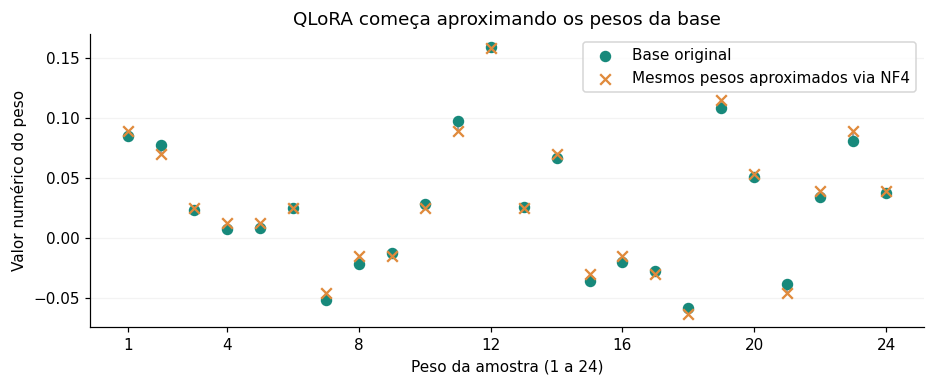

In [8]:
W_quant = modelo_base.p["1.fc"]
q = quantizar_nf4(W_quant)                  # aproxima a matriz congelada
W_reconstruida = desquantizar(q)           # recupera valores para os cálculos

originais = W_quant.ravel()[:24]
aproximados = W_reconstruida.ravel()[:24]
posicoes = np.arange(1,25)
diferencas = np.abs(originais-aproximados)

# Três exemplos numéricos do mesmo trecho desenhado no gráfico.
indices = sorted({0,int(np.argmax(diferencas)),23})
mostrar("O mesmo peso, antes e depois da quantização",
    ["Peso na amostra","Original","Aproximado via NF4","Diferença absoluta"],
    [(int(i+1),f"{originais[i]:.6f}",f"{aproximados[i]:.6f}",f"{diferencas[i]:.6f}") for i in indices],
    "Estes valores pertencem à base antes do ajuste. Ainda não são uma avaliação das respostas do modelo.")

fig,ax = plt.subplots(figsize=(8.6,3.6))
ax.vlines(posicoes,np.minimum(originais,aproximados),np.maximum(originais,aproximados),
          color="#737B85",linewidth=1.5,alpha=0.7,zorder=1)
ax.scatter(posicoes,originais,color=TEAL,marker="o",s=42,
           label="Base original",zorder=2)
ax.scatter(posicoes,aproximados,color=AMBER,marker="x",s=48,
           label="Mesmos pesos aproximados via NF4",zorder=3)
ax.set(xlabel="Peso da amostra (1 a 24)",ylabel="Valor numérico do peso",
       title="QLoRA começa aproximando os pesos da base")
ax.set_xticks([1,4,8,12,16,20,24])
ax.grid(axis="y",alpha=0.15)
ax.legend()
fig.tight_layout()
plt.show()

*italicized text*### Como escolhemos uma taxa para cada método?

Abaixo usamos uma **busca prévia registrada**, não executada novamente neste percurso: cinco taxas por método, escolhidas pelo acerto na validação e, em caso de empate, pela menor perda na validação. O teste não participa dessa regra.

Os registros mínimos de cada tentativa estão embutidos na próxima célula; você pode abri-la e conferir a escolha. Reproduzir a busca completa exige treinar as 15 tentativas. Aqui treinamos só a configuração escolhida de cada método, para manter a execução curta.

Partimos sempre de cópias da mesma base, sem replay e com um Adam novo. Os valores dos pesos congelados da QLoRA são diferentes após a quantização; por isso também avaliamos a **base quantizada antes do ajuste**.

## 4. Treinar os três métodos e comparar as respostas

Agora vamos adaptar cópias da mesma base usando ajuste completo, LoRA e QLoRA.

Todos recebem as mesmas 600 conversas e fazem 300 passos com lotes de 32. Cada método usa uma taxa de aprendizado previamente escolhida na validação.

Depois, fazemos os mesmos pedidos aos modelos para verificar:

- **Respostas:** conseguem responder corretamente e encerrar a resposta?
- **Retenção:** continuam completando os fatos e prevendo os textos antigos?

Também avaliamos a base quantizada sem ajuste. Assim, podemos observar o efeito da quantização antes de treinar seu adapter.

O acerto nas perguntas exige a resposta inteira igual à referência e o marcador de fim. Uma resposta escrita de outra maneira pode não receber o ponto, mesmo contendo o fato correto.

**Observe as tabelas em conjunto:** melhorar nas respostas de chat não garante preservar o desempenho nos textos antigos. Os resultados deste pequeno experimento também não estabelecem um vencedor geral entre os métodos.

In [9]:
# Taxas previamente escolhidas na validação.
# Esta célula usa diretamente os valores, sem repetir a busca.
LR_COMPLETO = 0.0002
LR_LORA = 0.001
LR_QLORA = 0.001

# Cada ajuste começa com uma cópia da mesma base.
print("Treinando o ajuste completo...")
completo = ajustar(
    ModeloPEFT(modelo_base, modo="completo"),
    lr=LR_COMPLETO,
)

print("Treinando a LoRA...")
lora = ajustar(
    ModeloPEFT(modelo_base, r=8, alpha=16, semente=3),
    lr=LR_LORA,
)

# Sem treinamento: cria a base quantizada para avaliar o ponto de partida.
# O adapter começa com correção zero.
base_nf4 = ModeloPEFT(
    modelo_base, r=1, alpha=1, nf4=True
).fundir()

print("Treinando a QLoRA didática...")
qlora = ajustar(
    ModeloPEFT(modelo_base, r=8, alpha=16, nf4=True, semente=3),
    lr=LR_QLORA,
)

# Mesmas avaliações para todos os estados.
modelos = [
    ("Base", modelo_base),
    ("Base em NF4", base_nf4),
    ("Ajuste completo", completo),
    ("LoRA", lora),
    ("QLoRA", qlora),
]
resultados = {nome: medir(modelo) for nome, modelo in modelos}

rotulos = {
    "Base": "Base original, sem ajuste",
    "Base em NF4": "Base quantizada, sem ajuste",
    "Ajuste completo": "Depois do ajuste completo",
    "LoRA": "Depois da LoRA",
    "QLoRA": "Depois da QLoRA didática",
}

# 1. Atendimento aos pedidos.
n_teste = len(CASOS["Teste"])
linhas = []

for nome, _ in modelos:
    medidas = resultados[nome]
    acertos = round(medidas["Teste"] * n_teste)
    linhas.append((
        rotulos[nome],
        f"{acertos}/{n_teste} ({pct(medidas['Teste'])})",
        pct(medidas["Formas novas"]),
        pct(medidas["2º turno"]),
    ))

mostrar(
    "1. O modelo aprendeu a responder?",
    ["Estado", "Acertos no teste", "Formas novas de pergunta", "Segundo turno"],
    linhas,
    "Os mesmos pedidos são usados em todos os modelos. "
    "No segundo turno, o avaliador fornece um histórico correto.",
)

# 2. Preservação das capacidades anteriores.
linhas = []

for nome, _ in modelos:
    medidas = resultados[nome]
    perda = f"{medidas['Perda no texto']:.2f}".replace(".", ",")
    linhas.append((
        rotulos[nome],
        pct(medidas["Completa fatos"]),
        perda,
    ))

mostrar(
    "2. O desempenho nos textos antigos foi preservado?",
    ["Estado", "Completa fatos: maior é melhor", "Perda no texto: menor é melhor"],
    linhas,
    "Completar fatos avalia frases como 'A capital da Noruega é...'. "
    "A perda mede a previsão dos textos antigos e não é um percentual.",
)

# 3. Um exemplo concreto da mesma pergunta em todos os modelos.
noruega = next(p for p in fora_teste if p[0] == "Noruega")
pedido = conversa(noruega, "capital", 0)[:-1]
linhas = []

for nome, modelo in modelos:
    resposta, terminou = responder(modelo, tok, [pedido])[0]
    linhas.append((
        rotulos[nome],
        tok.decodificar(resposta),
        "Sim" if terminou else "Não",
    ))

mostrar(
    "3. Qual é a capital da Noruega?",
    ["Estado", "Resposta gerada", "Encerrou a resposta?"],
    linhas,
    "Este exemplo ajuda a visualizar a mudança. "
    "As tabelas anteriores avaliam um conjunto maior de perguntas.",
)

Treinando o ajuste completo...
Treinando a LoRA...
Treinando a QLoRA didática...


Estado,Acertos no teste,Formas novas de pergunta,Segundo turno
"Base original, sem ajuste","0/165 (0,0%)","0,0%","0,0%"
"Base quantizada, sem ajuste","0/165 (0,0%)","0,0%","0,0%"
Depois do ajuste completo,"145/165 (87,9%)","80,3%","59,1%"
Depois da LoRA,"148/165 (89,7%)","86,4%","90,9%"
Depois da QLoRA didática,"150/165 (90,9%)","86,4%","90,9%"


Estado,Completa fatos: maior é melhor,Perda no texto: menor é melhor
"Base original, sem ajuste","100,0%","0,61"
"Base quantizada, sem ajuste","100,0%","0,61"
Depois do ajuste completo,"99,2%","1,61"
Depois da LoRA,"96,8%","2,43"
Depois da QLoRA didática,"96,0%","2,47"


Estado,Resposta gerada,Encerrou a resposta?
"Base original, sem ajuste",6. Qual é a língua mais falada da Coreia do Sul? <|endoftext|> A língua,Não
"Base quantizada, sem ajuste",6. Qual é a língua mais falada da Coreia do Sul? <|endoftext|> A língua,Não
Depois do ajuste completo,A capital da Noruega é Oslo.,Sim
Depois da LoRA,A capital da Noruega é Oslo.,Sim
Depois da QLoRA didática,A capital da Noruega é Oslo.,Sim


## 5. Onde está a economia de memória?

Mesmo congelada, a base continua ocupando espaço. A LoRA acrescenta o adapter, mas reduz os **gradientes** e os dois estados do **Adam**, pois só eles precisam acompanhar os parâmetros treináveis.

A tabela calcula pesos + gradientes + Adam em float32, por modelo. Não inclui ativações, temporários, caches ou vários modelos residentes ao mesmo tempo. Congelar pesos não elimina todas essas outras parcelas.

Na QLoRA mostramos o tamanho **ideal com códigos empacotados de 4 bits** e, separadamente, os arrays que esta simulação mantém.

In [10]:
def memoria_kb(m):
    adapters = sum(A.size + B.size for A, B in m.lora.values())
    pesos = 4 * sum(v.size for k, v in m.pesos.items() if k not in m.quant)
    pesos += sum(bits_armazenados(q) for q in m.quant.values()) / 8 + 4 * adapters
    t = m.n_treinaveis()
    return {"pesos": pesos / 1024, "gradientes": 4 * t / 1024, "Adam": 8 * t / 1024}
linhas=[]
for nome,m in [("Completo",completo),("LoRA",lora),("QLoRA: formato compacto ideal",qlora)]:
    mem=memoria_kb(m)
    linhas.append((nome,f"{mem['pesos']:.1f}",f"{mem['gradientes']:.1f}",f"{mem['Adam']:.1f}",f"{sum(mem.values()):.1f}"))
mostrar("Contabilidade por modelo, em KiB",["Método","Pesos","Gradientes","Adam","Soma"],linhas,
    "QLoRA: armazenamento compacto hipotético. Nos demais, pesos e estados em float32. As ativações não estão nesta soma.")
arrays_q = sum(v.nbytes for v in qlora.pesos.values())+sum(v.nbytes for v in qlora.p.values())
arrays_q += sum(v.nbytes for quant in qlora.quant.values() for v in quant.values() if isinstance(v,np.ndarray))

Método,Pesos,Gradientes,Adam,Soma
Completo,517.0,517.0,1034.0,2068.0
LoRA,581.0,64.0,128.0,773.0
QLoRA: formato compacto ideal,246.6,64.0,128.0,438.6


## 6. Guardar o adapter e fazer o merge

O adapter permite reutilizar a mesma base em adaptações diferentes. Para reconstruir o modelo, os valores de $A$ e $B$ precisam acompanhar **identificação da base, rank, alpha, módulos-alvo, tokenizador/template e informação de quantização**. Aqui montamos esse pacote na memória, sem gravar um checkpoint em disco.

O **merge** soma a correção: $W_{novo}=W+(\alpha/r)AB$. Na avaliação, sem dropout, essa é a mesma expressão matemática do caminho separado. A ordem das operações em ponto flutuante pode introduzir diferenças pequenas; vamos medir os logits e o acerto.

Na QLoRA distinguimos somar sobre a base desquantizada de **quantizar novamente o resultado da soma**. A nova quantização introduz outra aproximação e pode mudar as respostas.

In [11]:
pacote_adapter={"config":{"base":"mini-GPT deste notebook, semente 0, 800 passos",
    "r":8,"alpha":16,"alvos":list(LINEARES),"nf4":False,"tokenizador":"tok deste notebook","template":"ChatML deste laboratório"},
    "pesos":lora.adaptador()}
restaurada=ModeloPEFT(modelo_base,**{k:pacote_adapter["config"][k] for k in ["r","alpha","alvos"]})
for nome,valor in pacote_adapter["pesos"].items():restaurada.p[nome][...] = valor
X=conversas_fixas(exemplos[:10],PAD)[0]
erro_recarregar=float(np.abs(lora.forward(X,guardar=False)-restaurada.forward(X,guardar=False)).max())
lora_fundida = lora.fundir()
X = conversas_fixas(exemplos[:64], PAD)[0]
print("Maior diferença de logits, adapter x fundido:", float(np.abs(lora.forward(X, guardar=False) - lora_fundida.forward(X, guardar=False)).max()))
resultados["LoRA fundida"] = medir(lora_fundida)

qlora_fundida = qlora.fundir()                       # soma sobre a base desquantizada
requant = MiniGPT.__new__(MiniGPT)
requant.__dict__.update({k: v for k, v in qlora_fundida.__dict__.items() if k != "p"})
requant.p = {k: (desquantizar(quantizar_nf4(v)) if k in qlora.quant else v.copy()) for k, v in qlora_fundida.p.items()}
resultados["QLoRA fundida e re-quantizada"] = medir(requant)

na_original = ModeloPEFT(modelo_base, r=8, alpha=16)  # adapter da QLoRA sobre a base original
for nome, (A_, B_) in qlora.lora.items():
    na_original.lora[nome][0][...] = A_
    na_original.lora[nome][1][...] = B_
resultados["Adapter QLoRA na base original"] = medir(na_original)

delta_merge=float(np.abs(lora.forward(X,guardar=False)-lora_fundida.forward(X,guardar=False)).max())
mostrar("Verificações do adapter e do merge",["Verificação","Resultado"],[
    ("Valores treináveis do adapter, sem a configuração",f"{4*lora.n_treinaveis()/1024:.1f} KiB"),
    ("Maior diferença de logits ao recolocar o adapter na base correta",f"{erro_recarregar:.2e}"),
    ("Maior diferença de logits após o merge LoRA",f"{delta_merge:.2e}")],
    "Diferenças numéricas pequenas são esperadas no merge. É preciso conferir também as respostas na forma final de uso.")
mostrar("A forma de implantação também precisa ser avaliada",["Estado","Acerto no mesmo teste"],
    [(nome,pct(resultados[nome]["Teste"])) for nome in ["LoRA","LoRA fundida","QLoRA","QLoRA fundida e re-quantizada","Adapter QLoRA na base original"]],
    "Trocar a base quantizada pela original não é apenas carregar o mesmo modelo. O adapter foi aprendido para uma base específica.")

Maior diferença de logits, adapter x fundido: 1.9073486328125e-05


Verificação,Resultado
"Valores treináveis do adapter, sem a configuração",64.0 KiB
Maior diferença de logits ao recolocar o adapter na base correta,0.00e+00
Maior diferença de logits após o merge LoRA,1.91e-05


Estado,Acerto no mesmo teste
LoRA,"89,7%"
LoRA fundida,"89,7%"
QLoRA,"90,9%"
QLoRA fundida e re-quantizada,"90,3%"
Adapter QLoRA na base original,"91,5%"
